In [1]:
import pandas as pd
import os
from lightgbm import LGBMClassifier
from numba.np.arrayobj import dtype_type
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score,f1_score
import shap
from sklearn.model_selection import GridSearchCV


df = pd.read_csv('E:/credit-risk-model/backend/data/raw/Credit_dataset/UCI_Credit_Card.csv')

print(df.shape)
print(df.columns.tolist())
df.head()
print(os.getcwd())

(30000, 25)
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']
E:\credit-risk-model


In [2]:
print("Missing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df['default.payment.next.month'].value_counts())
print(df['default.payment.next.month'].value_counts(normalize=True)*100)

Missing values:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

Class distribution:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: f

In [3]:
neg = df['default.payment.next.month'].value_counts()[0]
pos = df['default.payment.next.month'].value_counts()[1]
scale_pos_weight = neg / pos
print(scale_pos_weight)

3.5207956600361663


In [4]:
model = LGBMClassifier(scale_pos_weight=scale_pos_weight,n_estimators=300,learning_rate=0.05,max_depth =6, random_state=42, verbose = -1)


In [5]:
X = df.drop(['ID', 'default.payment.next.month'], axis=1)
y = df['default.payment.next.month']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (24000, 23)
Test shape: (6000, 23)


In [6]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred_proba =model.predict_proba(X_test)[:,1]


In [7]:
print(classification_report(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-Auc Score",roc_auc_score(y_test, y_pred_proba))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.47      0.60      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.71      0.68      6000
weighted avg       0.79      0.76      0.77      6000

Confusion matrix:
[[3770  903]
 [ 525  802]]
ROC-Auc Score 0.7740052484482116


In [8]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

E:\credit-risk-model\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [9]:
print(type(shap_values))
if isinstance(shap_values, list):
    print("length:", len(shap_values))
    print("shape of each:", shap_values)
else:
    print("Shape:", shap_values.shape)

<class 'numpy.ndarray'>
Shape: (6000, 23)


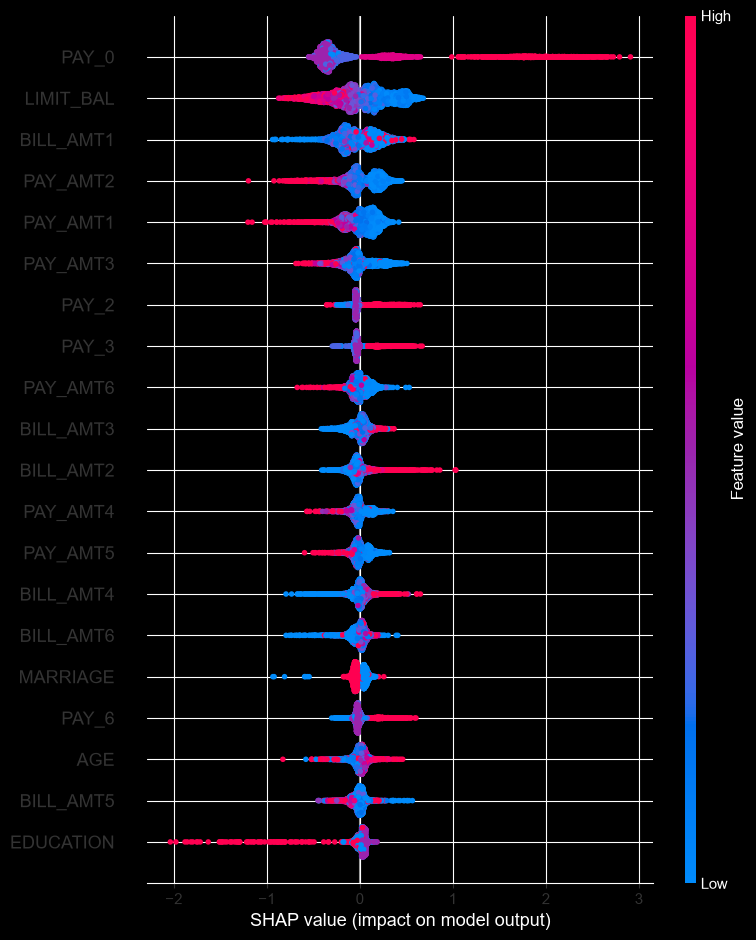

In [10]:
shap.summary_plot(shap_values, X_test)


In [11]:
param_grid = {
    'max_depth': [4,6,8],
    'n_estimators': [200,300,400],
    'learning_rate': [0.01,0.5,0.1],
    'num_leaves': [20,31,40]

}

grid_search = GridSearchCV(
    estimator=LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42, verbose=-1),
    param_grid=param_grid,
    scoring='f1',
    cv = 3,
    n_jobs=-1,
    verbose=1)
grid_search.fit(X_train, y_train)

print("Best params:",grid_search.best_params_)
print("Best F1 Score (CV):", grid_search.best_score_)


Best params: {'learning_rate': 0.01, 'max_depth': 8, 'n_estimators': 200, 'num_leaves': 40}
Best F1 Score (CV): 0.545229343952155


In [12]:
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score (CV):", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.01, 'max_depth': 8, 'n_estimators': 200, 'num_leaves': 40}
Best F1 Score (CV): 0.545229343952155


In [18]:
best_model = LGBMClassifier(
    learning_rate=0.1,
    max_depth=8,
    n_estimators=200,
    num_leaves=40,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbose=-1
)

best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:,1]

In [19]:
print(classification_report(y_test, y_pred_best))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_best))
print("ROC-Auc Score",roc_auc_score(y_test, y_pred_proba))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.48      0.60      0.53      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.70      0.69      6000
weighted avg       0.79      0.77      0.77      6000

Confusion matrix:
[[3798  875]
 [ 535  792]]
ROC-Auc Score 0.7667041709407939


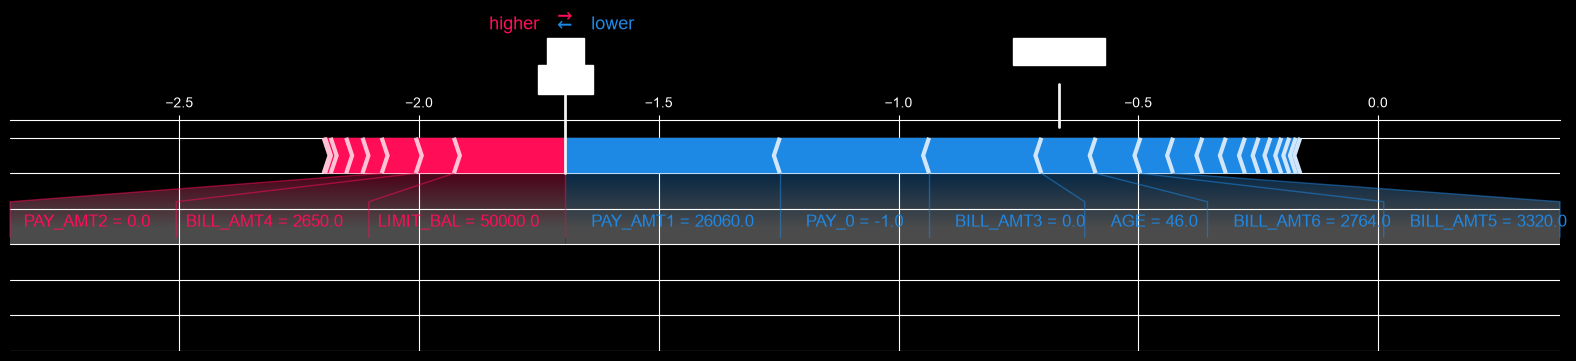

In [20]:
explainer_best = shap.TreeExplainer(best_model)
shap_values_best = explainer_best.shap_values(X_test)

sample_idx = 0

shap.force_plot(
    explainer_best.expected_value,
    shap_values_best[sample_idx],
    X_test.iloc[sample_idx],
    matplotlib=True



)

In [21]:
# 1. Average payment delay across 6 months
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
df['avg_pay_delay'] = df[pay_cols].mean(axis=1)

# 2. Max payment delay (worst month)
df['max_pay_delay'] = df[pay_cols].max(axis=1)

# 3. Utilization ratio (average bill / credit limit)
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
df['avg_bill_amt'] = df[bill_cols].mean(axis=1)
df['utilization_ratio'] = df['avg_bill_amt'] / (df['LIMIT_BAL'] + 1)  # +1 taaki divide by zero na ho

# 4. Total bill amount
df['total_bill_amt'] = df[bill_cols].sum(axis=1)

# 5. Total payment amount
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
df['total_pay_amt'] = df[pay_amt_cols].sum(axis=1)

# 6. Payment ratio (kitna % bill wapas kiya)
df['payment_ratio'] = df['total_pay_amt'] / (df['total_bill_amt'] + 1)

df[['avg_pay_delay', 'max_pay_delay', 'utilization_ratio', 'total_bill_amt', 'total_pay_amt', 'payment_ratio']].head()

,avg_pay_delay,max_pay_delay,utilization_ratio,total_bill_amt,total_pay_amt,payment_ratio
0,-0.333333,2,0.064197,7704.0,689.0,0.089422
1,0.500000,2,0.023718,17077.0,5000.0,0.292774
2,0.000000,0,0.188244,101653.0,11018.0,0.108387
3,0.000000,0,0.771098,231334.0,8388.0,0.036259
4,-0.333333,0,0.364456,109339.0,59049.0,0.540049


In [22]:
new_features = ['avg_pay_delay', 'max_pay_delay', 'avg_bill_amt', 'utilization_ratio',
                 'total_bill_amt', 'total_pay_amt', 'payment_ratio']

X = df.drop(['ID', 'default.payment.next.month'], axis=1)
y = df['default.payment.next.month']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("New shape:", X_train.shape)

New shape: (24000, 30)


In [23]:
best_model.fit(X_train, y_train)
y_pred_fe = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred_fe))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_fe))
print("ROC-Auc Score",roc_auc_score(y_test, y_pred_proba))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.47      0.60      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000

Confusion matrix:
[[3782  891]
 [ 528  799]]
ROC-Auc Score 0.7707105756408852


In [25]:
import os
os.makedirs('../models', exist_ok=True)

In [27]:
import joblib

joblib.dump(best_model, '../models/model.pkl')

joblib.dump(X_train.columns.tolist(), '../models/feature_names.pkl')

print("Model saved successfully!")

Model saved successfully!


In [30]:
print(X_train.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'avg_pay_delay', 'max_pay_delay', 'avg_bill_amt', 'utilization_ratio', 'total_bill_amt', 'total_pay_amt', 'payment_ratio']


In [33]:
import os
print(os.path.abspath('../models/model.pkl'))
print(os.path.exists('../models/model.pkl'))


E:\models\model.pkl
True


In [34]:
import os
import joblib

save_dir = r'E:\credit-risk-model\backend\models'
os.makedirs(save_dir, exist_ok=True)

joblib.dump(best_model, os.path.join(save_dir, 'model.pkl'))
joblib.dump(X_train.columns.tolist(), os.path.join(save_dir, 'feature_names.pkl'))

print("Saved successfully at:", save_dir)

Saved successfully at: E:\credit-risk-model\backend\models
